# D₂/H₂ selectivity from single-component isotherms (IAST)

Workflow: read the isotherm table from a Micromeritics 3Flex Excel report → fit a dual-site Langmuir model to H₂ and D₂
isotherms at 77 K (pyGAPS) → predict the adsorbed-phase composition of an equimolar mixture with IAST → D₂/H₂ selectivity
as a function of total pressure.

> **Data note.** The isotherms used here are **synthetic demo data** (dual-site Langmuir curves with 1 % noise).
> The measured isotherms belong to an unpublished study and are not included.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import logging
import pygaps
from pygaps.prediction.iast import iast_point_fraction

In [2]:
# Reads the adsorption table from a Micromeritics Excel report
def extract_adsorption(filepath):
    sheet_name = 'Isoth...r Absolute Plot'   # sheet name as written in the 3Flex export
    df_raw = pd.read_excel(filepath, sheet_name=sheet_name)
    header_row_idx = df_raw[df_raw.apply(lambda row: row.astype(str).str.contains('Absolute Pressure').any(), axis=1)].index[0]

    df = pd.read_excel(filepath, sheet_name=sheet_name, header=header_row_idx + 1)
    adsorption_df = df.iloc[:, [0, 1]].dropna().reset_index(drop=True)

    adsorption_df['Absolute Pressure (mmHg)'] = pd.to_numeric(adsorption_df['Absolute Pressure (mmHg)'])
    adsorption_df['Quantity Adsorbed (mmol/g)'] = pd.to_numeric(adsorption_df['Quantity Adsorbed (mmol/g)'])

    return adsorption_df

# With instrument files:
# isotherms = {name: extract_adsorption(path) for name, path in file_paths.items()}

# Demo data (same two columns as the instrument table)
isotherms = {
    "Demo_H2": pd.read_csv("data/demo_H2_77K.csv"),
    "Demo_D2": pd.read_csv("data/demo_D2_77K.csv"),
}
print(isotherms["Demo_H2"].head())

   Absolute Pressure (mmHg)  Quantity Adsorbed (mmol/g)
0                     2.250                      0.0539
1                     3.363                      0.0779
2                     5.027                      0.1099
3                     7.514                      0.1525
4                    11.231                      0.2095


## Selectivity calculation

Points read for H2: 24
Points read for D2: 24


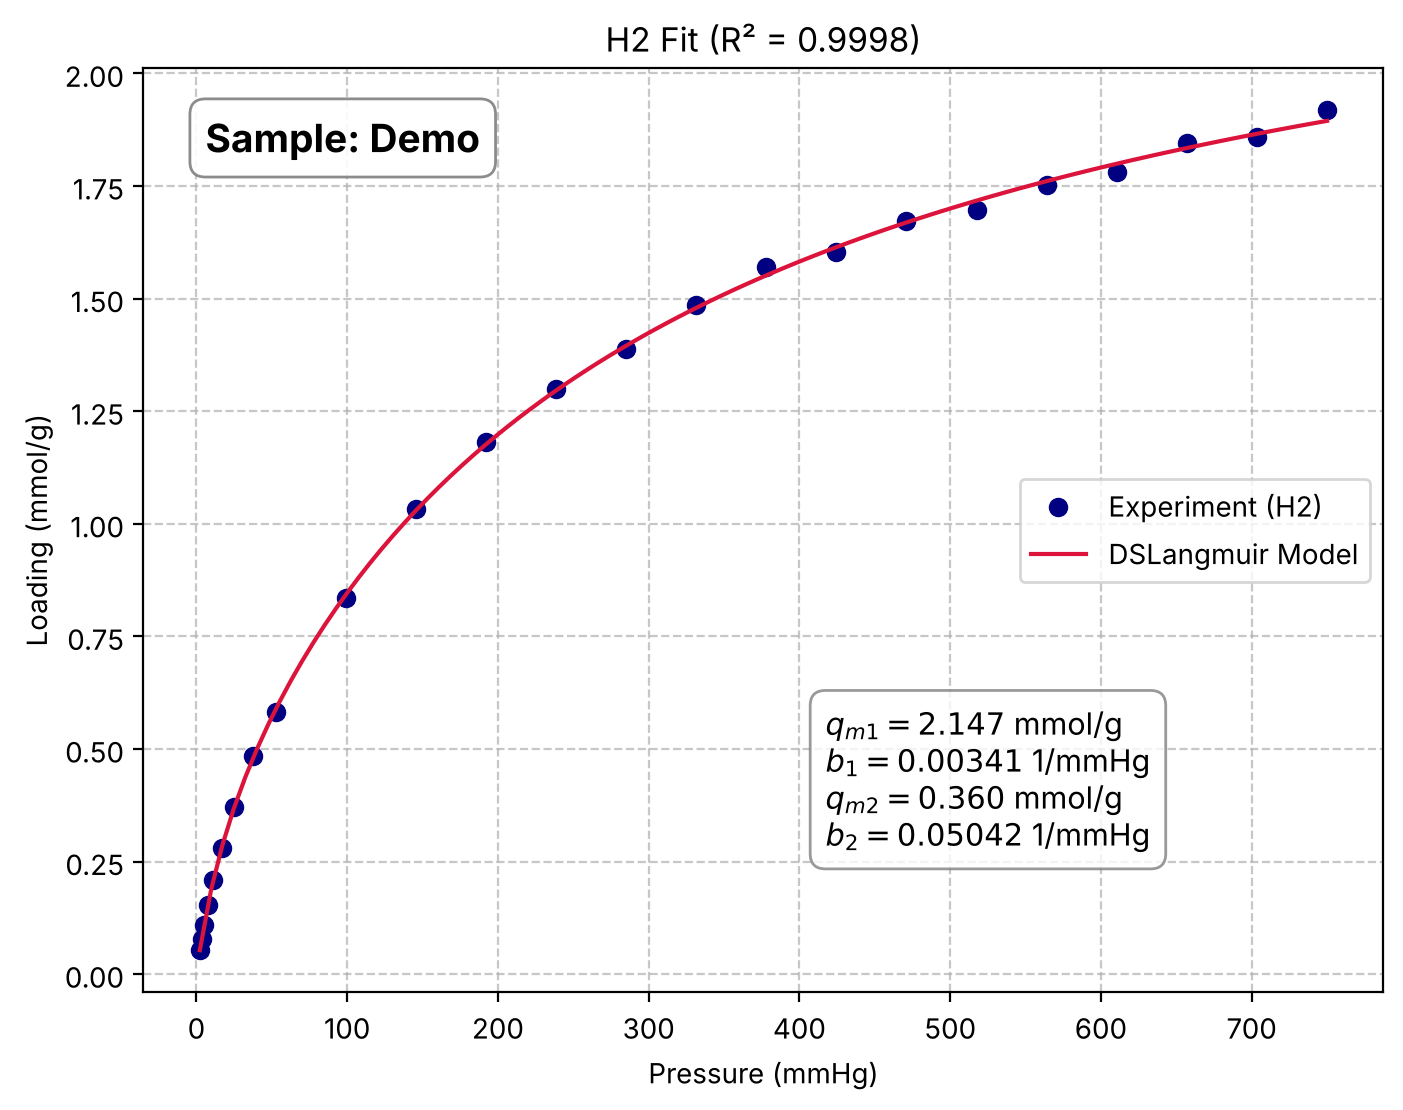

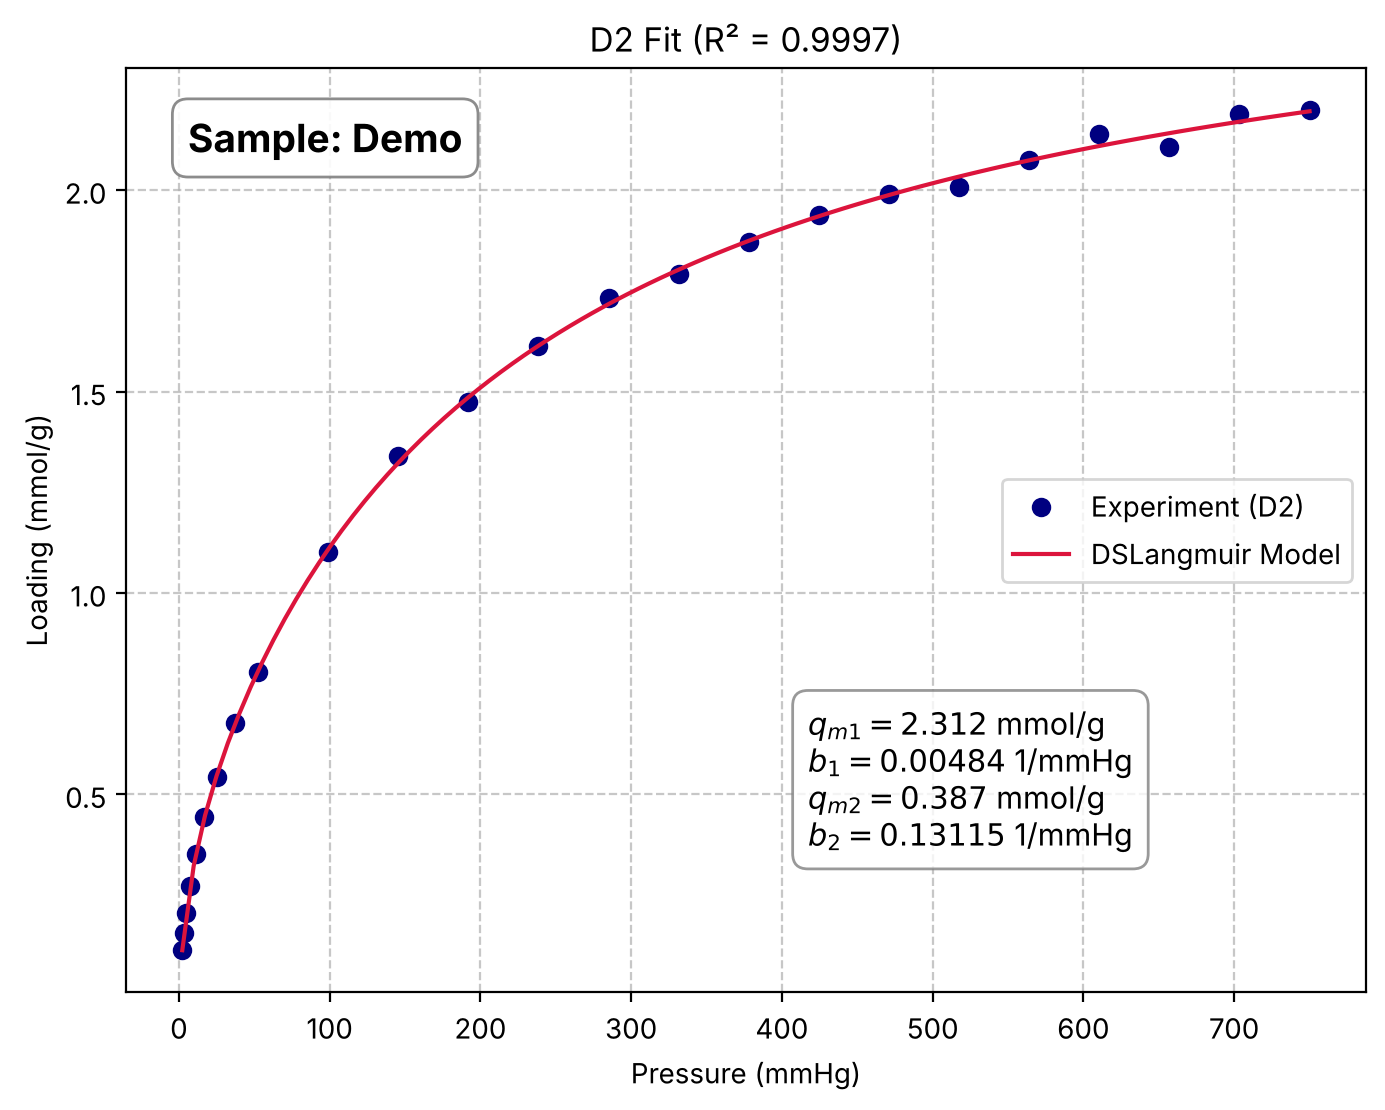

=== IAST results ===
 Pressure (bar)  D2/H2 Selectivity
           0.05              2.108
           0.10              1.996
           0.15              1.941
           0.20              1.911
           0.25              1.892
           0.30              1.880
           0.35              1.872
           0.40              1.867
           0.45              1.864
           0.50              1.862
           0.55              1.861
           0.60              1.861
           0.65              1.861
           0.70              1.862
           0.75              1.863
           0.80              1.864
           0.85              1.866
           0.90              1.868
           0.95              1.869
           1.00              1.871


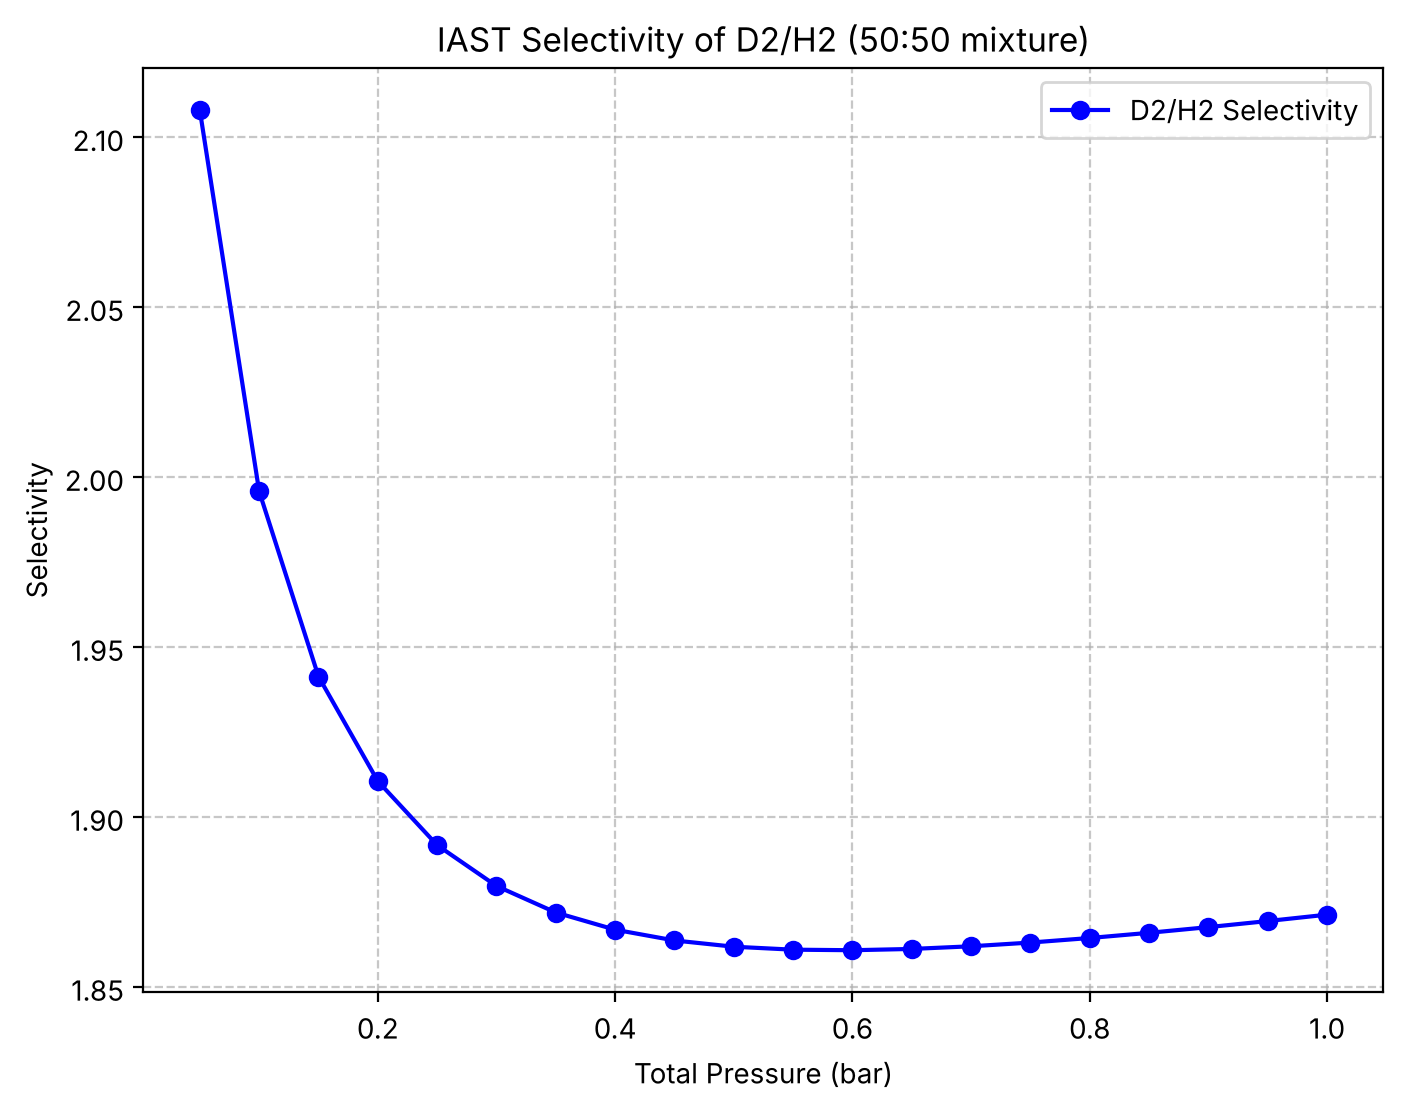

In [3]:
# ---------------------------------------------------------
# Step 1: PointIsotherm objects
# ---------------------------------------------------------
iso_h2 = pygaps.PointIsotherm(
    isotherm_data=isotherms["Demo_H2"],
    pressure_key='Absolute Pressure (mmHg)',
    loading_key='Quantity Adsorbed (mmol/g)',
    material='Demo', adsorbate='H2', temperature=77.0,
    pressure_mode='absolute', pressure_unit='mmHg',
    loading_basis='molar', loading_unit='mmol',
    material_basis='mass', material_unit='g', temperature_unit='K'
)

iso_d2 = pygaps.PointIsotherm(
    isotherm_data=isotherms["Demo_D2"],
    pressure_key='Absolute Pressure (mmHg)',
    loading_key='Quantity Adsorbed (mmol/g)',
    material='Demo', adsorbate='D2', temperature=77.0,
    pressure_mode='absolute', pressure_unit='mmHg',
    loading_basis='molar', loading_unit='mmol',
    material_basis='mass', material_unit='g', temperature_unit='K'
)

print(f"Points read for H2: {len(isotherms['Demo_H2'])}")
print(f"Points read for D2: {len(isotherms['Demo_D2'])}")

# ---------------------------------------------------------
# Step 2: fit the dual-site Langmuir model
# ---------------------------------------------------------
def calculate_r2(point_iso, model_iso):
    p_exp = point_iso.pressure()
    q_exp = point_iso.loading()
    q_mod = model_iso.loading_at(p_exp)
    ss_res = np.sum((q_exp - q_mod) ** 2)
    ss_tot = np.sum((q_exp - np.mean(q_exp)) ** 2)
    return 1 - ss_res / ss_tot

def fit_dsl(iso):
    return pygaps.ModelIsotherm(
        pressure=iso.pressure(), loading=iso.loading(),
        material=iso.material, adsorbate=iso.adsorbate.name,
        temperature=iso.temperature, pressure_mode=iso.pressure_mode,
        pressure_unit=iso.pressure_unit, loading_basis=iso.loading_basis,
        loading_unit=iso.loading_unit, material_basis=iso.material_basis,
        material_unit=iso.material_unit, temperature_unit=iso.temperature_unit,
        model='DSLangmuir'
    )

model_h2 = fit_dsl(iso_h2)
model_d2 = fit_dsl(iso_d2)

bbox_props = dict(boxstyle="round,pad=0.5", fc="white", ec="gray", alpha=0.8)
sample_name = "Demo"

for gas, iso, model in (("H2", iso_h2, model_h2), ("D2", iso_d2, model_d2)):
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.plot(iso.pressure(), iso.loading(), marker='o', linestyle='None', color='navy', label=f'Experiment ({gas})')
    p_smooth = np.linspace(min(iso.pressure()), max(iso.pressure()), 100)
    ax.plot(p_smooth, model.loading_at(p_smooth), linestyle='-', color='crimson', label='DSLangmuir Model')

    params = model.model.params
    text = (
        f"$q_{{m1}} = {params.get('n_m1', 0):.3f}$ mmol/g\n"
        f"$b_1 = {params.get('K1', 0):.5f}$ 1/mmHg\n"
        f"$q_{{m2}} = {params.get('n_m2', 0):.3f}$ mmol/g\n"
        f"$b_2 = {params.get('K2', 0):.5f}$ 1/mmHg"
    )
    ax.text(0.55, 0.15, text, transform=ax.transAxes, fontsize=11, verticalalignment='bottom', bbox=bbox_props)
    ax.text(0.05, 0.95, f"Sample: {sample_name}", transform=ax.transAxes, fontsize=14, fontweight='bold',
            verticalalignment='top', bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="gray", alpha=0.9))
    ax.set_title(f"{gas} Fit (R² = {calculate_r2(iso, model):.4f})")
    ax.set_xlabel('Pressure (mmHg)')
    ax.set_ylabel('Loading (mmol/g)')
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend(loc='center right')
    plt.show()

# ---------------------------------------------------------
# Step 3: IAST selectivity for a 50:50 mixture
# ---------------------------------------------------------
warnings.filterwarnings('ignore')
pygaps.logger.setLevel(logging.ERROR)

pressures_bar = np.arange(0.05, 1.05, 0.05)
selectivities = []
valid_pressures = []

for p_bar in pressures_bar:
    p_mmHg = p_bar * 750.062
    try:
        q_mix = iast_point_fraction(
            isotherms=[model_h2, model_d2],
            gas_mole_fraction=[0.5, 0.5],
            total_pressure=p_mmHg,
            verbose=False
        )
        q_h2_mix, q_d2_mix = q_mix[0], q_mix[1]
        sel = (q_d2_mix / 0.5) / (q_h2_mix / 0.5)   # D2/H2 selectivity
        selectivities.append(sel)
        valid_pressures.append(p_bar)
    except Exception:
        pass   # skip pressures where IAST does not converge

results_df = pd.DataFrame({'Pressure (bar)': valid_pressures, 'D2/H2 Selectivity': selectivities})
print("=== IAST results ===")
print(results_df.round({'Pressure (bar)': 2, 'D2/H2 Selectivity': 3}).to_string(index=False))

plt.figure(figsize=(8, 6))
plt.plot(valid_pressures, selectivities, marker='o', linestyle='-', color='b', label='D2/H2 Selectivity')
plt.title('IAST Selectivity of D2/H2 (50:50 mixture)')
plt.xlabel('Total Pressure (bar)')
plt.ylabel('Selectivity')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()